<a href="https://colab.research.google.com/github/Budhilata/hyperlocal-marketplace-for-local-vendors/blob/main/Student_Performance_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Setup is ready!")

Setup is ready!


In [ ]:
data = {
    "study_hours": [1, 2, 2, 3, 4, 4, 5, 6, 7, 8, 9, 10],
    "final_marks": [35, 40, 43, 48, 55, 58, 62, 68, 73, 80, 85, 92]
}

df = pd.DataFrame(data)

df.head()


,study_hours,final_marks
0,1,35
1,2,40
2,2,43
3,3,48
4,4,55


       study_hours  final_marks
count    12.000000    12.000000
mean      5.083333    61.583333
std       2.937480    18.446277
min       1.000000    35.000000
25%       2.750000    46.750000
50%       4.500000    60.000000
75%       7.250000    74.750000
max      10.000000    92.000000


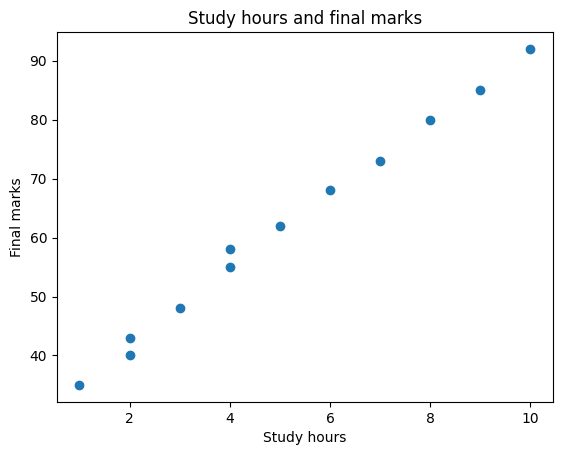

In [ ]:
print(df.describe())

plt.scatter(df["study_hours"], df["final_marks"])
plt.xlabel("Study hours")
plt.ylabel("Final marks")
plt.title("Study hours and final marks")
plt.show()


In [ ]:
X = df[["study_hours"]]
y = df["final_marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training complete!")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Model training complete!
Training rows: 9
Testing rows: 3


In [ ]:
predictions = model.predict(X_test)

print("Actual marks:   ", list(y_test))
print("Predicted marks:", [round(x, 1) for x in predictions])
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("R²:", round(r2_score(y_test, predictions), 2))

Actual marks:    [85, 80, 35]
Predicted marks: [np.float64(86.4), np.float64(80.1), np.float64(36.2)]
MAE: 0.89
R²: 1.0


In [ ]:
new_student = pd.DataFrame({"study_hours": [5]})
predicted_marks = model.predict(new_student)

print("Predicted marks:", round(predicted_marks[0], 1))

Predicted marks: 61.3


In [ ]:
data = {
    "study_hours":    [1, 2, 2, 3, 4, 4, 5, 6, 7, 8, 9, 10],
    "attendance":     [60, 65, 70, 68, 75, 80, 78, 85, 88, 90, 92, 95],
    "previous_marks": [35, 40, 42, 45, 50, 55, 58, 62, 68, 72, 78, 85],
    "final_marks":    [38, 42, 45, 48, 55, 59, 63, 68, 74, 80, 86, 92]
}

df = pd.DataFrame(data)
df.head()

,study_hours,attendance,previous_marks,final_marks
0,1,60,35,38
1,2,65,40,42
2,2,70,42,45
3,3,68,45,48
4,4,75,50,55


In [ ]:
print("Dataset size:", df.shape)
print("\nColumn information:")
print(df.info())
print("\nSummary:")
print(df.describe())
print("\nMissing values:")
print(df.isnull().sum())

Dataset size: (12, 4)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   study_hours     12 non-null     int64
 1   attendance      12 non-null     int64
 2   previous_marks  12 non-null     int64
 3   final_marks     12 non-null     int64
dtypes: int64(4)
memory usage: 516.0 bytes
None

Summary:
       study_hours  attendance  previous_marks  final_marks
count    12.000000   12.000000       12.000000    12.000000
mean      5.083333   78.833333       57.500000    62.500000
std       2.937480   11.440227       15.923111    17.830005
min       1.000000   60.000000       35.000000    38.000000
25%       2.750000   69.500000       44.250000    47.250000
50%       4.500000   79.000000       56.500000    61.000000
75%       7.250000   88.500000       69.000000    75.500000
max      10.000000   95.000000       85.000000    92.000000

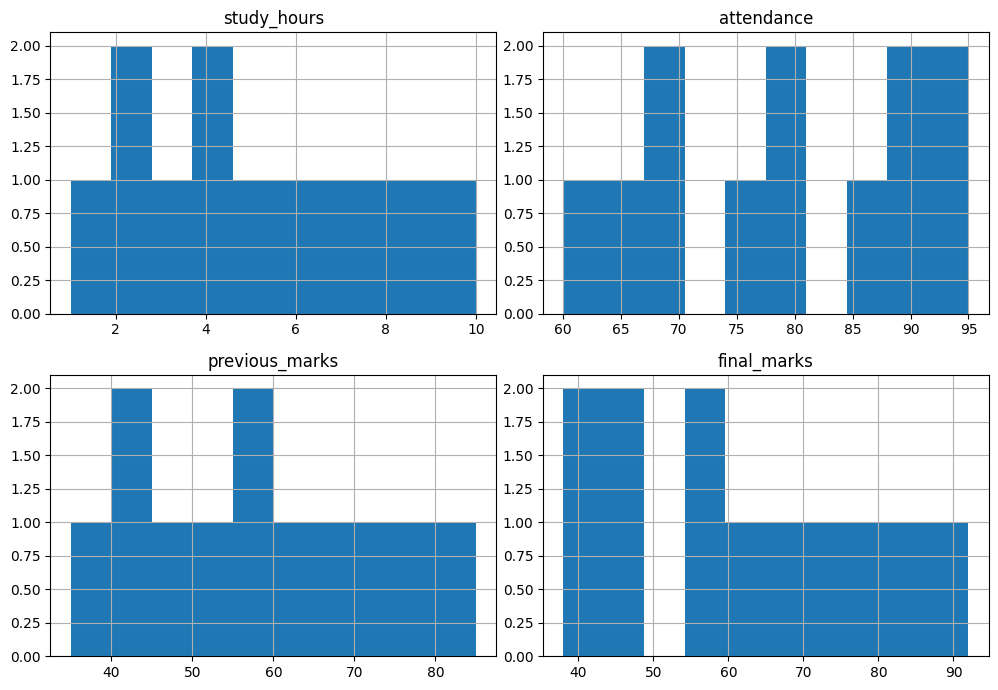

In [ ]:
df[["study_hours", "attendance", "previous_marks", "final_marks"]].hist(
    figsize=(10, 7)
)
plt.tight_layout()
plt.show()

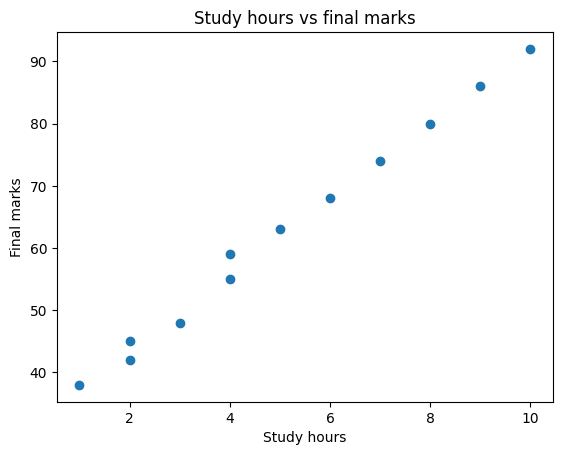

In [ ]:
plt.scatter(df["study_hours"], df["final_marks"])
plt.xlabel("Study hours")
plt.ylabel("Final marks")
plt.title("Study hours vs final marks")
plt.show()

In [ ]:
X = df[["study_hours", "attendance", "previous_marks"]]
y = df["final_marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual marks:   ", list(y_test))
print("Predicted marks:", [round(x, 1) for x in predictions])
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("R²:", round(r2_score(y_test, predictions), 2))

Actual marks:    [86, 80, 38]
Predicted marks: [np.float64(85.1), np.float64(79.0), np.float64(36.5)]
MAE: 1.13
R²: 1.0


In [ ]:
import numpy as np

np.random.seed(42)
n = 50

study_hours = np.random.randint(1, 11, n)
attendance = np.random.randint(55, 101, n)
previous_marks = np.random.randint(35, 91, n)

final_marks = (
    2.5 * study_hours
    + 0.25 * attendance
    + 0.45 * previous_marks
    + np.random.normal(0, 4, n)
)

final_marks = np.clip(final_marks, 0, 100).round(1)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_marks": previous_marks,
    "final_marks": final_marks
})

df.to_csv("student_data.csv", index=False)

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (50, 4)


,study_hours,attendance,previous_marks,final_marks
0,7,89,67,71.1
1,4,68,39,40.4
2,8,71,76,66.3
3,5,90,73,68.6
4,7,94,75,75.3


In [ ]:
print("Dataset size:", df.shape)

print("\nColumn types and non-null values:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset size: (50, 4)

Column types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   study_hours     50 non-null     int64  
 1   attendance      50 non-null     int64  
 2   previous_marks  50 non-null     int64  
 3   final_marks     50 non-null     float64
dtypes: float64(1), int64(3)
memory usage: 1.7 KB

Summary statistics:


,study_hours,attendance,previous_marks,final_marks
count,50.000000,50.000000,50.000000,50.000000
mean,5.840000,76.820000,61.880000,61.158000
std,2.698148,13.595753,15.712519,12.364665
min,1.000000,55.000000,35.000000,38.900000
25%,4.000000,65.750000,48.000000,51.475000
50%,6.000000,77.500000,65.000000,61.000000
75%,8.000000,89.000000,73.000000,70.250000
max,10.000000,99.000000,89.000000,93.500000



Missing values per column:
study_hours       0
attendance        0
previous_marks    0
final_marks       0
dtype: int64


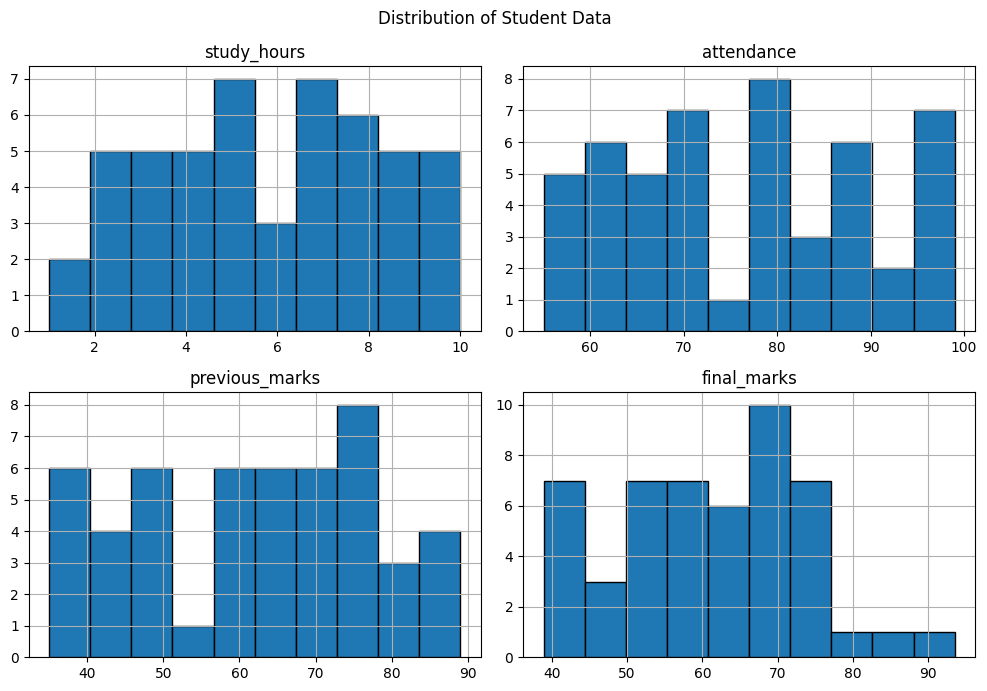

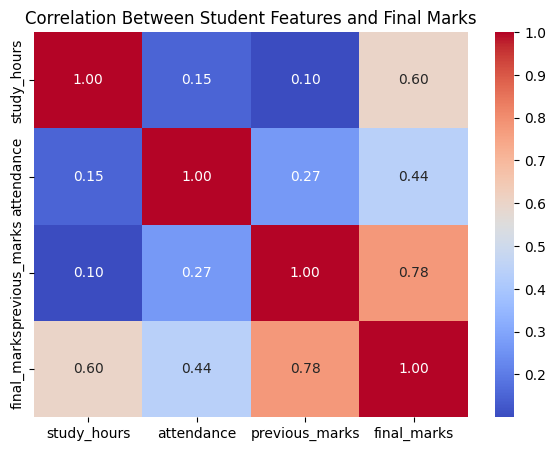

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Har column ke values ka distribution
df.hist(figsize=(10, 7), bins=10, edgecolor="black")
plt.suptitle("Distribution of Student Data")
plt.tight_layout()
plt.show()

# Features aur final marks ke beech correlation
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Student Features and Final Marks")
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X = df[["study_hours", "attendance", "previous_marks"]]
y = df["final_marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² score:", round(r2, 2))

Training rows: 40
Testing rows: 10
MAE: 3.12
RMSE: 3.7
R² score: 0.87


,Actual Marks,Predicted Marks
0,66.5,73.9
1,54.1,53.7
2,51.4,56.6
3,72.0,69.1
4,64.6,68.8
5,56.0,53.3
6,82.6,85.7
7,51.3,54.2
8,76.2,78.0
9,57.4,58.0


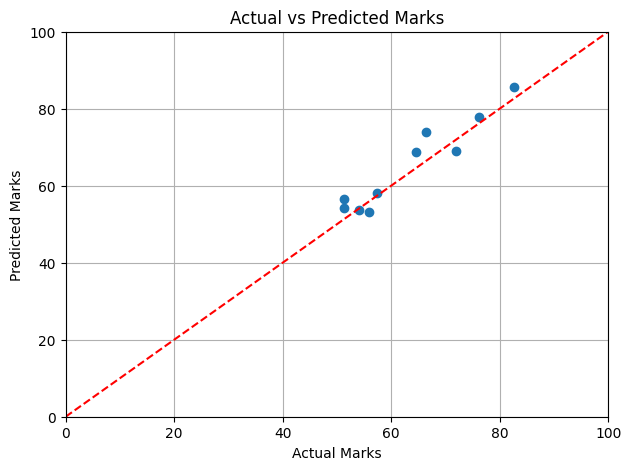

In [ ]:
results = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": predictions.round(1)
})

display(results)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions)
plt.plot([0, 100], [0, 100], "r--")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(True)
plt.show()

In [ ]:
study = float(input("Study hours per day (1-10): "))
attendance_value = float(input("Attendance percentage (55-100): "))
previous = float(input("Previous marks (0-100): "))

new_student = pd.DataFrame({
    "study_hours": [study],
    "attendance": [attendance_value],
    "previous_marks": [previous]
})

prediction = model.predict(new_student)[0]
prediction = max(0, min(100, prediction))

print(f"Estimated final marks: {prediction:.1f} / 100")

Study hours per day (1-10): 56
Attendance percentage (55-100): 55
Previous marks (0-100): 34
Estimated final marks: 100.0 / 100


In [ ]:
files.download("student_data.csv"))

SyntaxError: unmatched ')' (2744424421.py, line 1)

In [ ]:
from google.colab import files
files.download("student_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
code = '''import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

df = pd.read_csv("student_data.csv")

X = df[["study_hours", "attendance", "previous_marks"]]
y = df["final_marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("R2 score:", round(r2_score(y_test, predictions), 2))

student = pd.DataFrame({
    "study_hours": [9],
    "attendance": [87],
    "previous_marks": [90]
})
result = model.predict(student)[0]
print("Estimated final marks:", round(max(0, min(100, result)), 1))
'''

with open("student_performance.py", "w") as file:
    file.write(code)

print("Created student_performance.py")

Created student_performance.py


In [ ]:
plt.savefig("student_data_charts.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

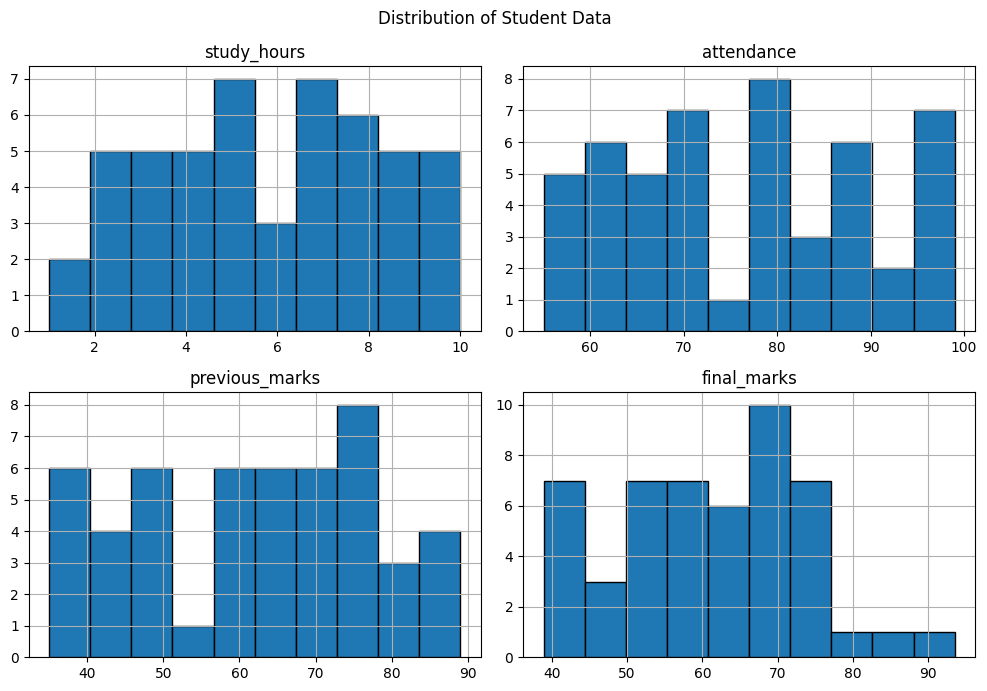

In [ ]:
df.hist(figsize=(10, 7), bins=10, edgecolor="black")
plt.suptitle("Distribution of Student Data")
plt.tight_layout()
plt.savefig("distribution_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
plt.savefig("correlation_chart.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Dono models ko same training data par train karo
linear_model = LinearRegression()
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)

linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

# Test data par predictions
linear_predictions = linear_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

# Results compare karo
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, tree_predictions)
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, tree_predictions)
    ]
})

comparison = comparison.round(2)
display(comparison)

,Model,MAE,R2 Score
0,Linear Regression,3.12,0.87
1,Decision Tree,8.17,-0.10


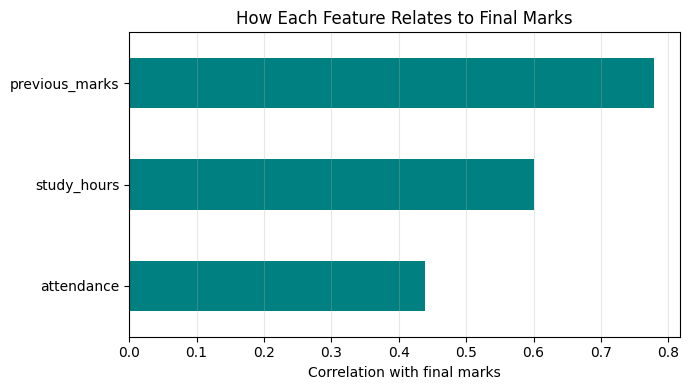

,Correlation with final marks
attendance,0.44
study_hours,0.60
previous_marks,0.78


In [ ]:
features = ["study_hours", "attendance", "previous_marks"]

correlations = df[features + ["final_marks"]].corr()["final_marks"].drop("final_marks")
correlations = correlations.sort_values()

plt.figure(figsize=(7, 4))
correlations.plot(kind="barh", color="teal")
plt.xlabel("Correlation with final marks")
plt.title("How Each Feature Relates to Final Marks")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("feature_relationships.png", dpi=150, bbox_inches="tight")
plt.show()

display(correlations.round(2).rename("Correlation with final marks").to_frame())

In [ ]:
correlations.round(2).rename("correlation_with_final_marks").to_csv(
    "feature_relationships.csv"
)

In [ ]:
features = ["study_hours", "attendance", "previous_marks"]

correlations = (
    df[features + ["final_marks"]]
    .corr()["final_marks"]
    .drop("final_marks")
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))
correlations.plot(kind="barh", color="teal", ax=ax)
ax.set_xlabel("Correlation with final marks")
ax.set_title("Feature Relationships with Final Marks")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig("feature_relationships.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

NameError: name 'df' is not defined

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_data.csv")
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'student_data.csv'

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 50

study_hours = np.random.randint(1, 11, n)
attendance = np.random.randint(55, 101, n)
previous_marks = np.random.randint(35, 91, n)

final_marks = (
    2.5 * study_hours
    + 0.25 * attendance
    + 0.45 * previous_marks
    + np.random.normal(0, 4, n)
)
final_marks = np.clip(final_marks, 0, 100).round(1)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_marks": previous_marks,
    "final_marks": final_marks
})

df.to_csv("student_data.csv", index=False)
print("Dataset ready:", df.shape)
display(df.head())

Dataset ready: (50, 4)


,study_hours,attendance,previous_marks,final_marks
0,7,89,67,71.1
1,4,68,39,40.4
2,8,71,76,66.3
3,5,90,73,68.6
4,7,94,75,75.3


NameError: name 'y_test' is not defined

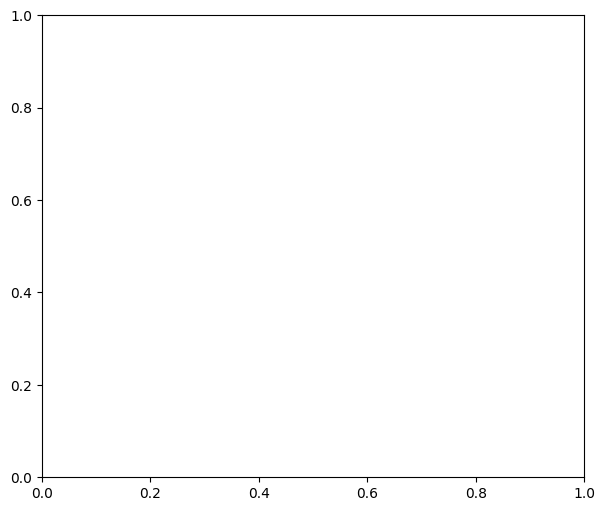

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, predictions, color="teal", label="Test students")
ax.plot([0, 100], [0, 100], "r--", label="Perfect prediction")
ax.set_xlabel("Actual marks")
ax.set_ylabel("Predicted marks")
ax.set_title("Actual vs Predicted Marks")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(project_folder / "actual_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

NameError: name 'project_folder' is not defined

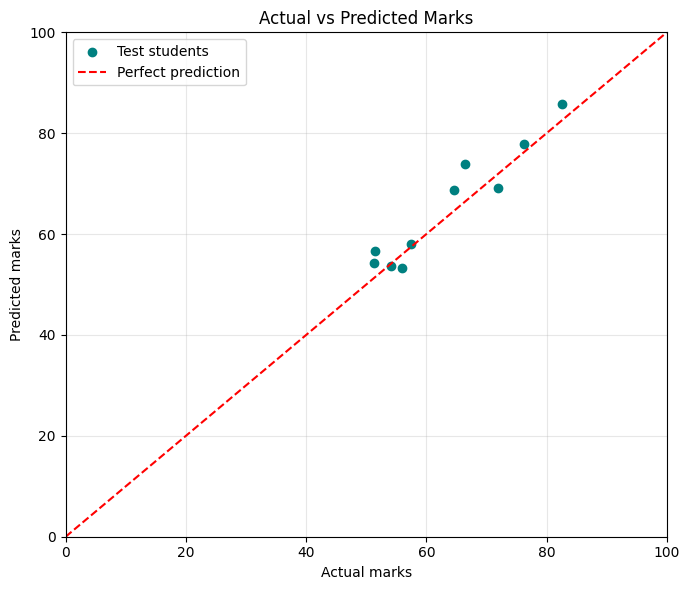

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = df[["study_hours", "attendance", "previous_marks"]]
y = df["final_marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, predictions, color="teal", label="Test students")
ax.plot([0, 100], [0, 100], "r--", label="Perfect prediction")
ax.set_xlabel("Actual marks")
ax.set_ylabel("Predicted marks")
ax.set_title("Actual vs Predicted Marks")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    project_folder / "actual_vs_predicted.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Chart saved to Google Drive:", project_folder / "actual_vs_predicted.png")

In [6]:
from pathlib import Path

project_folder = Path("/content/drive/MyDrive/Student_Performance_Project")
project_folder.mkdir(parents=True, exist_ok=True)

print("Drive folder ready:", project_folder)

Drive folder ready: /content/drive/MyDrive/Student_Performance_Project


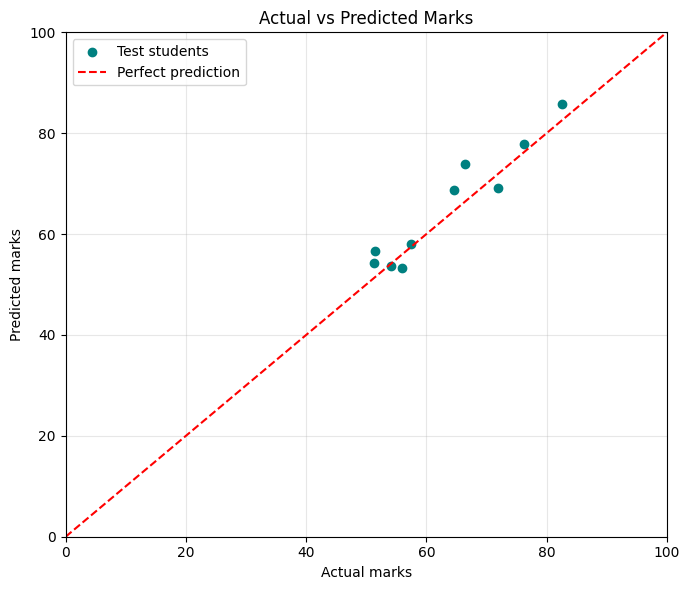

Chart saved to Google Drive: /content/drive/MyDrive/Student_Performance_Project/actual_vs_predicted.png


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = df[["study_hours", "attendance", "previous_marks"]]
y = df["final_marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, predictions, color="teal", label="Test students")
ax.plot([0, 100], [0, 100], "r--", label="Perfect prediction")
ax.set_xlabel("Actual marks")
ax.set_ylabel("Predicted marks")
ax.set_title("Actual vs Predicted Marks")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    project_folder / "actual_vs_predicted.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Chart saved to Google Drive:", project_folder / "actual_vs_predicted.png")

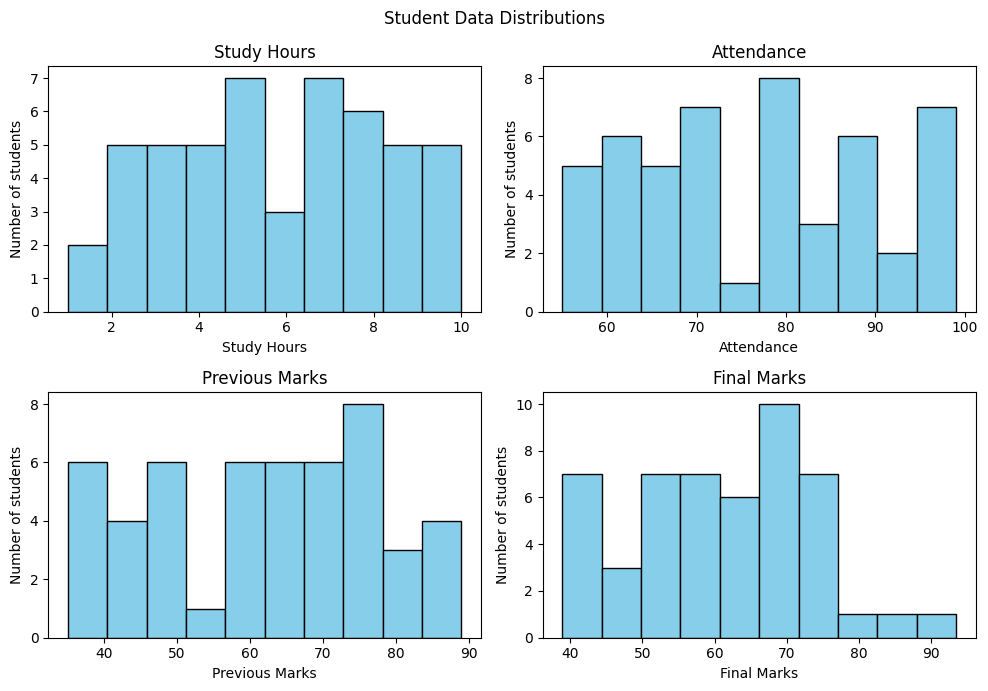

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
columns = ["study_hours", "attendance", "previous_marks", "final_marks"]

for ax, column in zip(axes.flat, columns):
    ax.hist(df[column], bins=10, edgecolor="black", color="skyblue")
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of students")

fig.suptitle("Student Data Distributions")
fig.tight_layout()
fig.savefig(project_folder / "distribution_charts.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

NameError: name 'comparison' is not defined

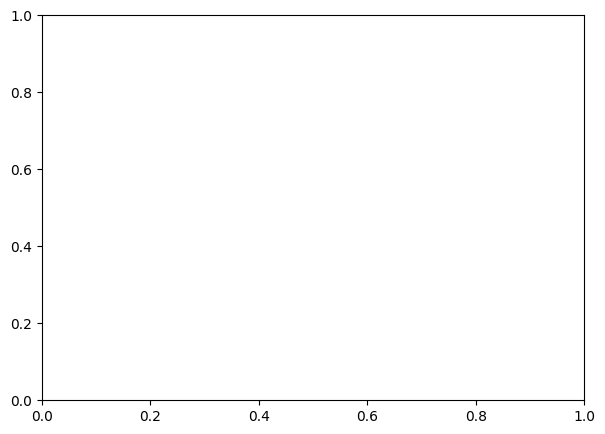

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
comparison.set_index("Model")["MAE"].plot(kind="bar", color=["teal", "orange"], ax=ax)
ax.set_ylabel("MAE (lower is better)")
ax.set_title("Model Comparison by Mean Absolute Error")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(project_folder / "model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

,Model,MAE
0,Linear Regression,3.12
1,Decision Tree,8.17


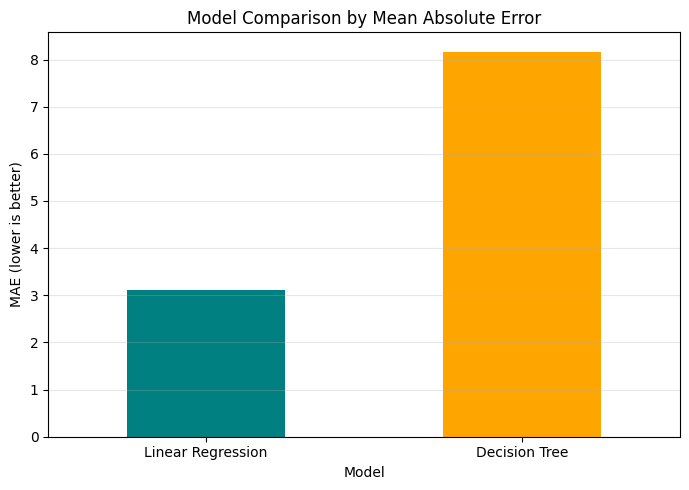

Saved: /content/drive/MyDrive/Student_Performance_Project/model_comparison.png


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

# Drive project folder
project_folder = Path("/content/drive/MyDrive/Student_Performance_Project")
project_folder.mkdir(parents=True, exist_ok=True)

# Data split
X = df[["study_hours", "attendance", "previous_marks"]]
y = df["final_marks"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train and compare models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42)
}

mae_scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    mae_scores[name] = mean_absolute_error(y_test, model.predict(X_test))

comparison = pd.DataFrame({
    "Model": list(mae_scores.keys()),
    "MAE": list(mae_scores.values())
})

display(comparison.round(2))

# Create and save comparison chart
fig, ax = plt.subplots(figsize=(7, 5))
comparison.set_index("Model")["MAE"].plot(
    kind="bar", color=["teal", "orange"], ax=ax
)
ax.set_ylabel("MAE (lower is better)")
ax.set_title("Model Comparison by Mean Absolute Error")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(project_folder / "model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", project_folder / "model_comparison.png")

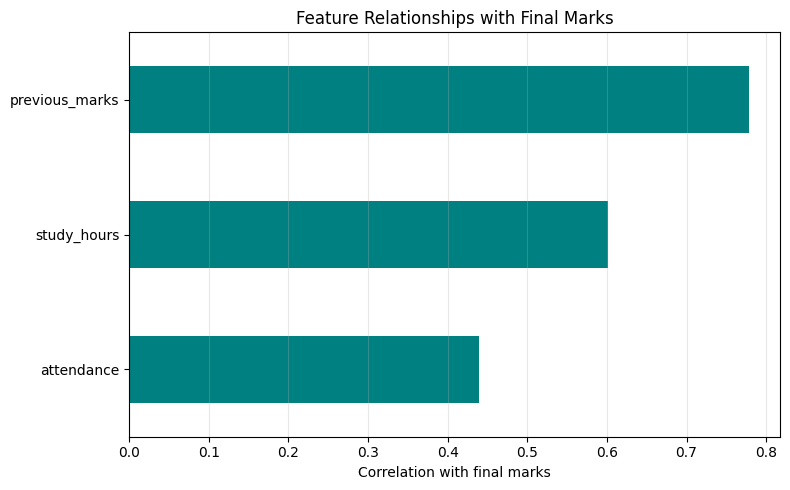

Saved: /content/drive/MyDrive/Student_Performance_Project/feature_relationships.png


In [11]:
import matplotlib.pyplot as plt
from pathlib import Path

project_folder = Path("/content/drive/MyDrive/Student_Performance_Project")
project_folder.mkdir(parents=True, exist_ok=True)

features = ["study_hours", "attendance", "previous_marks"]
correlations = (
    df[features + ["final_marks"]]
    .corr()["final_marks"]
    .drop("final_marks")
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))
correlations.plot(kind="barh", color="teal", ax=ax)
ax.set_xlabel("Correlation with final marks")
ax.set_title("Feature Relationships with Final Marks")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    project_folder / "feature_relationships.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved:", project_folder / "feature_relationships.png")